# **16.  Relación con la regresión logística.**

Temas selectos de aprendizaje de máquina \
Ana Luisa Llamas Martinez

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    log_loss
)

## 16.3 Recuperamos el problema de la práctica anterior.

In [2]:
wine = load_wine()

X = wine.data
y = wine.target

In [3]:
wine.target_names

array(['class_0', 'class_1', 'class_2'], dtype='<U7')

In [4]:
X.shape


(178, 13)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

## 16.4 Recuperamos la selección de la SVM.

In [6]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [7]:
pipeline_svc = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "svc",
        SVC()
    )
])

In [8]:
param_grid = [
    
    {
        "svc__kernel": ["linear"],
        "svc__C": [
            0.01,
            0.1,
            1,
            10,
            100
        ]
    },
    
    {
        "svc__kernel": ["rbf"],
        "svc__C": [
            0.01,
            0.1,
            1,
            10,
            100
        ],
        "svc__gamma": [
            0.001,
            0.01,
            0.1,
            1,
            10
        ]
    },
    
    {
        "svc__kernel": ["poly"],
        "svc__C": [
            0.1,
            1,
            10
        ],
        "svc__degree": [
            2,
            3,
            4
        ],
        "svc__gamma": ["scale"],
        "svc__coef0": [1]
    }
]

In [9]:
grid_svm = GridSearchCV(
    estimator = pipeline_svc,
    param_grid= param_grid,
    cv = cv,
    scoring="accuracy",
    n_jobs = -1
)

grid_svm.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...svc', SVC())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'svc__C': [0.01, 0.1, ...], 'svc__kernel': ['linear']}, {'svc__C': [0.01, 0.1, ...], 'svc__gamma': [0.001, 0.01, ...], 'svc__kernel': ['rbf']}, ...]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... 

In [10]:
grid_svm.best_params_

{'svc__C': 0.1, 'svc__kernel': 'linear'}

In [11]:
grid_svm.best_score_

np.float64(0.992)

In [12]:
mejor_svm = grid_svm.best_estimator_

## 16.5 Construimos la regresión logística.

In [13]:
modelo_logistico = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "logistic",
        LogisticRegression(
            max_iter=1000
        )
    )
])

modelo_logistico.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('logistic', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


## 16.7 Ahora sí: evaluación sobre test.

In [14]:
pred_svm = mejor_svm.predict(X_test)

pred_log = modelo_logistico.predict(X_test)

In [15]:
acc_svm = accuracy_score(y_test, pred_svm)

acc_svm

0.9629629629629629

In [16]:
acc_svm = accuracy_score(y_test, pred_log)

acc_svm

0.9814814814814815

## 16.8 Matriz de confusión de la SVM.

In [17]:
cm_svm = confusion_matrix(
    y_test, pred_svm
)

cm_svm

array([[18,  0,  0],
       [ 1, 19,  1],
       [ 0,  0, 15]])

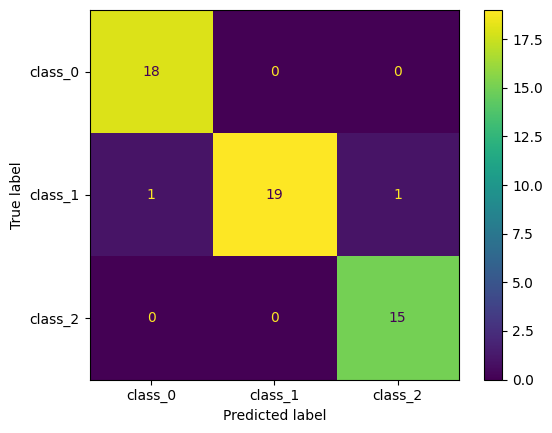

In [18]:
ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=wine.target_names
).plot()
plt.show()

## 16.9 Matriz de confusión de regresión logística.

In [19]:
cm_log = confusion_matrix(
    y_test, pred_log
)

cm_log

array([[18,  0,  0],
       [ 1, 20,  0],
       [ 0,  0, 15]])

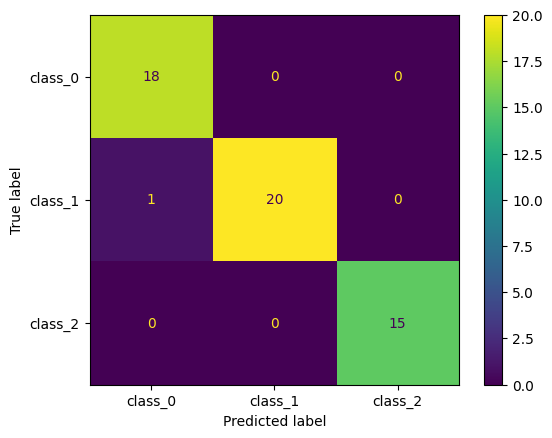

In [20]:
ConfusionMatrixDisplay(
    confusion_matrix=cm_log,
    display_labels=wine.target_names
).plot()
plt.show()

## 16.10 Precision, recall y F1.

In [21]:
print(
    classification_report(y_test, pred_svm, target_names=wine.target_names)
)

              precision    recall  f1-score   support

     class_0       0.95      1.00      0.97        18
     class_1       1.00      0.90      0.95        21
     class_2       0.94      1.00      0.97        15

    accuracy                           0.96        54
   macro avg       0.96      0.97      0.96        54
weighted avg       0.97      0.96      0.96        54



In [22]:
print(
    classification_report(y_test, pred_log, target_names=wine.target_names)
)

              precision    recall  f1-score   support

     class_0       0.95      1.00      0.97        18
     class_1       1.00      0.95      0.98        21
     class_2       1.00      1.00      1.00        15

    accuracy                           0.98        54
   macro avg       0.98      0.98      0.98        54
weighted avg       0.98      0.98      0.98        54



## 16.14 Visualicemos ambas pérdidas.

In [23]:
m = np.linspace(-4,4,400)

In [24]:
prob_log = modelo_logistico.predict_proba(X_test)

prob_log

array([[9.90734414e-01, 8.83183589e-03, 4.33749989e-04],
       [2.26955261e-03, 9.96689670e-01, 1.04077696e-03],
       [9.99963345e-01, 9.68794813e-06, 2.69670837e-05],
       [9.99053535e-01, 1.63087572e-04, 7.83377491e-04],
       [7.54731765e-01, 2.43282814e-01, 1.98542115e-03],
       [9.99483966e-01, 2.74814968e-04, 2.41219170e-04],
       [4.96623827e-03, 1.17376339e-03, 9.93859998e-01],
       [2.90127350e-04, 9.99459932e-01, 2.49941005e-04],
       [1.86804689e-01, 8.11372314e-01, 1.82299655e-03],
       [2.88821624e-02, 2.27441246e-01, 7.43676592e-01],
       [2.13206852e-02, 7.13735923e-01, 2.64943392e-01],
       [7.17791140e-02, 9.28094538e-01, 1.26348484e-04],
       [1.49355907e-03, 1.36448031e-04, 9.98369993e-01],
       [3.77454662e-03, 9.95976535e-01, 2.48918175e-04],
       [9.91381594e-01, 8.46394808e-03, 1.54457567e-04],
       [1.75239912e-03, 1.83520805e-03, 9.96412393e-01],
       [3.46585045e-03, 9.96198807e-01, 3.35342919e-04],
       [9.18860077e-01, 7.87209

In [25]:
prob_log[:5]

array([[9.90734414e-01, 8.83183589e-03, 4.33749989e-04],
       [2.26955261e-03, 9.96689670e-01, 1.04077696e-03],
       [9.99963345e-01, 9.68794813e-06, 2.69670837e-05],
       [9.99053535e-01, 1.63087572e-04, 7.83377491e-04],
       [7.54731765e-01, 2.43282814e-01, 1.98542115e-03]])

In [26]:
np.argmax(prob_log[:5], axis = 1)

array([0, 1, 0, 0, 0])

In [27]:
log_loss_log = log_loss(
    y_test, prob_log
)

log_loss_log

0.0777991620425924

## Ejercicios

**16.24.1 Ejercicio 1. Comparar predicciones.** Identifica las observaciones del conjunto de prueba para las cuales la SVM y la regresión logística producen predicciones diferentes.

¿Cuántas son?

In [28]:
pred_svm

array([0, 1, 0, 0, 0, 0, 2, 1, 1, 2, 2, 1, 2, 1, 0, 2, 1, 0, 2, 2, 1, 2,
       2, 2, 0, 2, 0, 1, 0, 1, 0, 1, 2, 1, 1, 2, 1, 1, 1, 0, 2, 0, 0, 0,
       0, 1, 1, 0, 2, 0, 1, 1, 2, 0])

In [29]:
pred_log

array([0, 1, 0, 0, 0, 0, 2, 1, 1, 2, 1, 1, 2, 1, 0, 2, 1, 0, 2, 2, 1, 2,
       2, 2, 0, 2, 0, 1, 0, 1, 0, 1, 2, 1, 1, 2, 1, 1, 1, 0, 2, 0, 0, 0,
       0, 1, 1, 0, 2, 0, 1, 1, 2, 0])

In [30]:
vectores = np.where(pred_svm != pred_log)[0]
print("Vectores donde las predicciones de SVM y la regresiòn logìstica son diferentes:", vectores)

Vectores donde las predicciones de SVM y la regresiòn logìstica son diferentes: [10]


**16.24.2 Ejercicio 2. Comparar las pérdidas.** Calcula la pérdida logística y la pérdida hinge para:

$$
m \in { -3, -2, -1, 0, 1, 2, 3 }
$$

Construye una tabla y explica qué ocurre cuando

$$
m \geq 1.
$$


In [31]:
m = [-3, -2, -1, 0, 1, 2, 3]
ll = []
lh = []
for i in m:
    loss_log = np.log(1 + np.exp(- i))
    loss_hinge = np.maximum(0, 1 - i)

    ll.append(loss_log)
    lh.append(loss_hinge)

In [32]:
tabla_resultados = {
    "m": m,
    "Pérdida logística": ll,
    "Pérdida Hinge": lh
}

tabla_resultados = pd.DataFrame(
    tabla_resultados
)

tabla_resultados


,m,Pérdida logística,Pérdida Hinge
0,-3,3.048587,4
1,-2,2.126928,3
2,-1,1.313262,2
3,0,0.693147,1
4,1,0.313262,0
5,2,0.126928,0
6,3,0.048587,0


Cuando $m=1$, la pérdida Hinge se vuelve cero. Ésto debido a cómo se calcula. En cambio, la pérdida logística sigue decayendo, aunque nunca toca cero.S

**16.24.3 Ejercicio 3. Probabilidades de regresión logística.** Selecciona las primeras diez observaciones del conjunto de prueba.

Obtén sus probabilidades estimadas.

Para cada observación identifica:

- la clase verdadera;
- la clase predicha;
- la probabilidad más alta;
- si la clasificación fue correcta.

In [46]:
prob_log = modelo_logistico.predict_proba(
    X_test[:10]
)

clase_verdadera = []
clase_predicha = []
prob_alta = []
clas_correcta = []

In [47]:
for i in range(10):

    cv = y_test[i]
    cp = modelo_logistico.classes_[np.argmax(prob_log[i])]
    pa = np.max(prob_log[i])
    cc = (cp == cv)

    clase_verdadera.append(cv)
    clase_predicha.append(cp)
    prob_alta.append(pa)
    clas_correcta.append(cc)

In [48]:
tabla_resultados3 = {
    "Clase verdadera": clase_verdadera,
    "Clase predicha": clase_predicha,
    "Probabilidad más alta": prob_alta,
    "Clasificación correcta": clas_correcta
}

tabla_resultados3 = pd.DataFrame(
    tabla_resultados3
)

tabla_resultados3

,Clase verdadera,Clase predicha,Probabilidad más alta,Clasificación correcta
0,0,0,0.990734,True
1,1,1,0.996690,True
2,0,0,0.999963,True
3,0,0,0.999054,True
4,0,0,0.754732,True
5,0,0,0.999484,True
6,2,2,0.993860,True
7,1,1,0.999460,True
8,1,1,0.811372,True
9,2,2,0.743677,True


**16.24.4 Ejercicio 4. Regularización en regresión logística.** Ajusta regresiones logísticas utilizando:

$$
C \in { 0.001, 0.01, 0.1, 1, 10, 100 }
$$

Utiliza validación cruzada sobre el conjunto de entrenamiento.

No utilices X_test para seleccionar C.

In [52]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

param_grid = {'C': [0.001, 0.01, 0.1, 1, 10, 100]}

modelo_log = LogisticRegression(max_iter=10000)

In [53]:
grid_search = GridSearchCV(
    estimator=modelo_log,
    param_grid=param_grid,
    cv=cv,
    scoring='accuracy'
)

In [54]:
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...ax_iter=10000)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of informatio

In [55]:
grid_search.best_params_

{'C': 10}